E-Commerce Sales Analysis and Customer Behavior Analysis

## 1. Import Libraries

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [78]:
# Seaborn and chart settings (used by all charts below)
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11

# Show numbers with thousand separators and 2 decimals
pd.options.display.float_format = '{:,.2f}'.format
pd.options.display.max_columns = 50

## 2. Load Dataset

In [79]:

df = pd.read_csv("../data/Ecommerce_sales.csv")

In [80]:
df.head()


,customer_id,session_id,visit_date,device_type,user_type,marketing_channel,product_id,product_category,unit_price,quantity,discount_percent,discount_amount,revenue,pages_viewed,time_on_site_sec,added_to_cart,purchased,cart_abandoned,rating,review_text,review_helpful_votes,payment_method,visit_day,visit_month,visit_weekday,visit_season,session_duration_bucket,revenue_normalized,location
0,1803,0,28-11-2024,2,1,2,894,6,651.57,1,20,130.31,0.00,21,965,1,0,1,4,1,0,1,28,11,3,0,Long,0.00,209
1,7964,1,25-09-2024,2,0,4,844,2,945.27,4,15,567.16,0.00,21,1158,0,0,0,4,1,0,2,25,9,2,0,Long,0.00,213
2,6890,2,31-05-2024,1,1,0,865,0,400.44,4,0,0.00,0.00,19,710,1,0,1,4,1,0,2,31,5,4,1,Short,0.00,10
3,4949,3,30-01-2024,1,0,2,851,3,"1,268.54",2,5,126.85,"2,410.23",19,1674,1,1,0,4,10,4,1,30,1,1,3,Very Long,0.31,46
4,4896,4,25-02-2024,1,1,5,794,3,880.81,3,0,0.00,0.00,13,427,1,0,1,4,1,0,1,25,2,6,3,Very Short,0.00,118


In [81]:
df.shape

(25000, 29)

In [82]:
df.columns

Index(['customer_id', 'session_id', 'visit_date', 'device_type', 'user_type',
       'marketing_channel', 'product_id', 'product_category', 'unit_price',
       'quantity', 'discount_percent', 'discount_amount', 'revenue',
       'pages_viewed', 'time_on_site_sec', 'added_to_cart', 'purchased',
       'cart_abandoned', 'rating', 'review_text', 'review_helpful_votes',
       'payment_method', 'visit_day', 'visit_month', 'visit_weekday',
       'visit_season', 'session_duration_bucket', 'revenue_normalized',
       'location'],
      dtype='object')

In [83]:
df.info(

)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 29 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              25000 non-null  int64  
 1   session_id               25000 non-null  int64  
 2   visit_date               25000 non-null  object 
 3   device_type              25000 non-null  int64  
 4   user_type                25000 non-null  int64  
 5   marketing_channel        25000 non-null  int64  
 6   product_id               25000 non-null  int64  
 7   product_category         25000 non-null  int64  
 8   unit_price               25000 non-null  float64
 9   quantity                 25000 non-null  int64  
 10  discount_percent         25000 non-null  int64  
 11  discount_amount          25000 non-null  float64
 12  revenue                  25000 non-null  float64
 13  pages_viewed             25000 non-null  int64  
 14  time_on_site_sec      

In [84]:
df.describe()

,customer_id,session_id,device_type,user_type,marketing_channel,product_id,product_category,unit_price,quantity,discount_percent,discount_amount,revenue,pages_viewed,time_on_site_sec,added_to_cart,purchased,cart_abandoned,rating,review_text,review_helpful_votes,payment_method,visit_day,visit_month,visit_weekday,visit_season,revenue_normalized,location
count,"25,000.00","25,000.00","25,000.00","25,000.00","25,000.00","25,000.00","25,000.00","25,000.00","25,000.00","25,000.00","25,000.00","25,000.00","25,000.00","25,000.00","25,000.00","25,000.00","25,000.00","25,000.00","25,000.00","25,000.00","25,000.00","25,000.00","25,000.00","25,000.00","25,000.00","25,000.00","25,000.00"
mean,"5,479.93","12,499.50",0.71,0.55,2.51,449.11,3.50,782.32,2.49,9.00,175.00,404.65,12.54,903.26,0.64,0.22,0.42,3.95,1.67,5.52,2.48,15.71,6.51,2.98,1.50,0.05,111.71
std,"2,593.54","7,217.02",0.64,0.50,1.70,259.51,2.29,476.61,1.11,9.26,269.01,"1,022.39",6.93,518.68,0.48,0.42,0.49,0.54,1.99,12.34,1.71,8.80,3.46,1.99,1.12,0.13,65.07
min,"1,000.00",0.00,0.00,0.00,0.00,0.00,0.00,50.05,1.00,0.00,0.00,0.00,1.00,10.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00,1.00,0.00,0.00,0.00,0.00
25%,"3,234.00","6,249.75",0.00,0.00,1.00,225.00,2.00,395.22,1.00,0.00,0.00,0.00,7.00,453.00,0.00,0.00,0.00,4.00,1.00,0.00,1.00,8.00,3.00,1.00,1.00,0.00,55.00
50%,"5,482.00","12,499.50",1.00,1.00,2.00,448.00,4.00,691.73,2.00,10.00,65.81,0.00,13.00,903.00,1.00,0.00,0.00,4.00,1.00,0.00,2.00,16.00,7.00,3.00,2.00,0.00,111.00
75%,"7,715.00","18,749.25",1.00,1.00,4.00,675.00,5.00,"1,096.84",3.00,15.00,240.36,0.00,19.00,"1,355.00",1.00,0.00,1.00,4.00,1.00,0.00,4.00,23.00,10.00,5.00,3.00,0.00,169.00
max,"9,998.00","24,999.00",2.00,1.00,5.00,898.00,7.00,"1,999.83",4.00,30.00,"2,388.26","7,889.36",24.00,"1,799.00",1.00,1.00,1.00,5.00,10.00,49.00,5.00,31.00,12.00,6.00,3.00,1.00,224.00


In [85]:
df.isnull().sum()

customer_id                0
session_id                 0
visit_date                 0
device_type                0
user_type                  0
marketing_channel          0
product_id                 0
product_category           0
unit_price                 0
quantity                   0
discount_percent           0
discount_amount            0
revenue                    0
pages_viewed               0
time_on_site_sec           0
added_to_cart              0
purchased                  0
cart_abandoned             0
rating                     0
review_text                0
review_helpful_votes       0
payment_method             0
visit_day                  0
visit_month                0
visit_weekday              0
visit_season               0
session_duration_bucket    0
revenue_normalized         0
location                   0
dtype: int64

In [86]:
df.duplicated().sum()

np.int64(0)

In [87]:
df["customer_id"].nunique()

8442

In [88]:
df["session_id"].nunique()

25000

In [89]:
df["product_id"].nunique()

899

In [90]:
missing = df.isnull().sum()

missing[missing > 0].sort_values(ascending=False)

Series([], dtype: int64)

In [91]:
df.duplicated().sum()

np.int64(0)

In [92]:
categorical_columns = [
    "device_type",
    "user_type",
    "marketing_channel",
    "product_category",
    "added_to_cart",
    "purchased",
    "cart_abandoned",
    "payment_method",
    "visit_season"
]

for col in categorical_columns:
    print("\n", col)
    print(df[col].value_counts())


 device_type
device_type
1    12600
0     9887
2     2513
Name: count, dtype: int64

 user_type
user_type
1    13782
0    11218
Name: count, dtype: int64

 marketing_channel
marketing_channel
2    4281
5    4263
1    4190
3    4116
4    4109
0    4041
Name: count, dtype: int64

 product_category
product_category
2    3237
4    3204
5    3149
0    3142
6    3112
7    3073
1    3043
3    3040
Name: count, dtype: int64

 added_to_cart
added_to_cart
1    16117
0     8883
Name: count, dtype: int64

 purchased
purchased
0    19384
1     5616
Name: count, dtype: int64

 cart_abandoned
cart_abandoned
0    14499
1    10501
Name: count, dtype: int64

 payment_method
payment_method
1    4281
4    4229
0    4227
3    4140
5    4072
2    4051
Name: count, dtype: int64

 visit_season
visit_season
3    6275
2    6269
1    6247
0    6209
Name: count, dtype: int64


In [93]:
df.nunique().sort_values()

user_type                      2
added_to_cart                  2
cart_abandoned                 2
purchased                      2
device_type                    3
session_duration_bucket        4
visit_season                   4
quantity                       4
rating                         5
marketing_channel              6
payment_method                 6
visit_weekday                  7
discount_percent               7
product_category               8
review_text                   11
visit_month                   12
pages_viewed                  24
visit_day                     31
review_helpful_votes          50
location                     225
visit_date                   365
product_id                   899
time_on_site_sec            1790
revenue                     5573
revenue_normalized          5573
customer_id                 8442
discount_amount            13189
unit_price                 23136
session_id                 25000
dtype: int64

In [94]:
df["device_type"].value_counts().sort_index()

device_type
0     9887
1    12600
2     2513
Name: count, dtype: int64

In [95]:
df["user_type"].value_counts().sort_index()

user_type
0    11218
1    13782
Name: count, dtype: int64

In [96]:
df["marketing_channel"].value_counts().sort_index()

marketing_channel
0    4041
1    4190
2    4281
3    4116
4    4109
5    4263
Name: count, dtype: int64

In [97]:
df["product_category"].value_counts().sort_index()

product_category
0    3142
1    3043
2    3237
3    3040
4    3204
5    3149
6    3112
7    3073
Name: count, dtype: int64

In [98]:
df["payment_method"].value_counts().sort_index()

payment_method
0    4227
1    4281
2    4051
3    4140
4    4229
5    4072
Name: count, dtype: int64

In [99]:
df["visit_season"].value_counts().sort_index()

visit_season
0    6209
1    6247
2    6269
3    6275
Name: count, dtype: int64

In [100]:
df["location"].nunique()

225

In [101]:
df["visit_date"] = pd.to_datetime(
    df["visit_date"],
    dayfirst=True
)

In [102]:
df["visit_date"].head()

0   2024-11-28
1   2024-09-25
2   2024-05-31
3   2024-01-30
4   2024-02-25
Name: visit_date, dtype: datetime64[ns]

## Data Cleaning
In the earlier cells we already **checked for missing values and duplicates** and **converted `visit_date` to a proper date**. Here we finish the cleaning with a few more checks. Each step is explained in simple language.

### Step 1 – Missing values
`df.isnull().sum()` showed **0 missing values** in every column, so nothing needs to be filled or removed. (Nothing is guessed or imputed, which is the safest choice when no values are missing.)

### Step 2 – Duplicate records
`df.duplicated().sum()` showed **0 duplicate rows**, and every `session_id` is unique, so no rows need to be removed. The code below is kept so that it still works if a different dataset is loaded.

In [103]:
rows_before = len(df)
df = df.drop_duplicates()
print('Rows before:', rows_before, '| Rows after removing duplicates:', len(df))

Rows before: 25000 | Rows after removing duplicates: 25000


### Step 3 – Data types
- `visit_date` was text (`28-11-2024`) and has been converted to **datetime**, so we can analyse months and weekdays.
- `customer_id`, `session_id` and `product_id` are **identifiers** – they are numbers, but we never calculate averages with them.
- `device_type`, `user_type`, `marketing_channel`, `product_category`, `payment_method`, `visit_season` and `location` are **codes (labels)**. We keep them as integers (so the earlier cells still work) but only **group and compare** them – we never average them.

### Step 4 – Check for inconsistent values (logic checks)
We test whether the columns agree with each other. Each check counts the **rows that break a rule**. A result of 0 means the data is consistent.

In [104]:
purchased_rows = df[df['purchased'] == 1]

checks = {
    'Purchased rows where revenue != price x quantity - discount':
        int((~np.isclose(purchased_rows['unit_price'] * purchased_rows['quantity']
                         - purchased_rows['discount_amount'],
                         purchased_rows['revenue'], atol=0.05)).sum()),
    'Rows with revenue > 0 but purchased = 0':
        int(((df['purchased'] == 0) & (df['revenue'] > 0)).sum()),
    'Rows with purchased = 1 but revenue = 0':
        int(((df['purchased'] == 1) & (df['revenue'] == 0)).sum()),
    'Rows purchased without being added to cart':
        int(((df['purchased'] == 1) & (df['added_to_cart'] == 0)).sum()),
    'Rows where cart_abandoned does not match (added to cart and not purchased)':
        int((df['cart_abandoned'] != ((df['added_to_cart'] == 1) & (df['purchased'] == 0)).astype(int)).sum()),
    'Rows with negative price, quantity or discount':
        int(((df['unit_price'] < 0) | (df['quantity'] < 0) | (df['discount_amount'] < 0)).sum()),
    'Rows with discount_percent outside 0-100':
        int((~df['discount_percent'].between(0, 100)).sum()),
    'Rows where visit_month / visit_day do not match visit_date':
        int(((df['visit_date'].dt.month != df['visit_month']) | (df['visit_date'].dt.day != df['visit_day'])).sum()),
}
display(pd.Series(checks, name='rows_breaking_rule').to_frame())

,rows_breaking_rule
Purchased rows where revenue != price x quantity - discount,0
Rows with revenue > 0 but purchased = 0,0
Rows with purchased = 1 but revenue = 0,0
Rows purchased without being added to cart,0
Rows where cart_abandoned does not match (added to cart and not purchased),0
"Rows with negative price, quantity or discount",0
Rows with discount_percent outside 0-100,0
Rows where visit_month / visit_day do not match visit_date,0


**Result:** all checks return 0. This tells us that
- `revenue = unit_price × quantity − discount_amount` for every purchase, so revenue is reliable.
- A **zero revenue is not an error** – it simply means the visitor did not buy. We therefore keep these rows.
- The date parts agree with `visit_date`.

### Step 5 – Look at unusual patterns in specific columns
Two things in the data need to be understood before we analyse it.

In [105]:
# (a) Does the same customer always have the same user_type?
customers_with_two_types = (df.groupby('customer_id')['user_type'].nunique() > 1).sum()
print('Customers that appear with more than one user_type code:', int(customers_with_two_types),
      'out of', df['customer_id'].nunique())

# (b) Which ratings do non-purchasing sessions have?
print()
print('Ratings found in sessions WITHOUT a purchase:', sorted(df.loc[df['purchased'] == 0, 'rating'].unique().tolist()))
print('Ratings found in sessions WITH a purchase   :', sorted(df.loc[df['purchased'] == 1, 'rating'].unique().tolist()))

Customers that appear with more than one user_type code: 5083 out of 8442

Ratings found in sessions WITHOUT a purchase: [4]
Ratings found in sessions WITH a purchase   : [1, 2, 3, 4, 5]


**What this means (important for the viva):**
- `user_type` changes between sessions of the same customer, so it describes the **session**, not a permanent customer type. We use it only to compare sessions.
- Every non-purchasing session has the same rating (4). This looks like a **default value**, not a real customer opinion. So we analyse **ratings only for purchasing sessions**.

### Step 6 – Check outliers (unusually large values)
We use the IQR rule: a value is an outlier if it is above **Q3 + 1.5 × IQR**. We check it on the order value of purchases.

In [106]:
purchases_check = df[df['purchased'] == 1]['revenue']
q1, q3 = purchases_check.quantile(0.25), purchases_check.quantile(0.75)
upper_limit = q3 + 1.5 * (q3 - q1)
outliers = purchases_check[purchases_check > upper_limit]

print('Upper outlier limit (Q3 + 1.5 x IQR): {:,.2f}'.format(upper_limit))
print('Number of purchases above this limit :', len(outliers))
print('Highest order value                  : {:,.2f}'.format(purchases_check.max()))

Upper outlier limit (Q3 + 1.5 x IQR): 5,251.87
Number of purchases above this limit : 214
Highest order value                  : 7,889.36


**Decision:** these large orders are **kept**. They are valid, because they come from high unit prices multiplied by a quantity of up to 4 (our logic check proved the numbers add up). Removing them would remove real, valuable sales.

### Step 7 – Create helpful new columns
We create a few columns from existing data to make the analysis easier. Nothing is invented – they are all calculated from existing columns.

In [107]:
# Weekday name taken directly from the date (Monday ... Sunday), in correct order
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['weekday'] = pd.Categorical(df['visit_date'].dt.day_name(), categories=weekday_order, ordered=True)

# Month number for sorting and a month period for time-series
df['month'] = df['visit_date'].dt.month
df['year_month'] = df['visit_date'].dt.to_period('M')

# Value of the basket before discount
df['gross_value'] = df['unit_price'] * df['quantity']

# Table with only the sessions that ended in a purchase (used for sales analysis)
purchases = df[df['purchased'] == 1].copy()

print('Total sessions :', len(df))
print('Purchase rows  :', len(purchases))

Total sessions : 25000
Purchase rows  : 5616


**Cleaning summary**
| Step | Action | Result |
|---|---|---|
| Missing values | Checked | None found, nothing changed |
| Duplicates | Checked | None found, nothing removed |
| Data types | Date converted; IDs and codes identified | Done |
| Consistency | 8 logic checks | All passed |
| Unusual values | Zero revenue, outliers, default ratings, `user_type` | Understood and handled carefully |

## Exploratory Data Analysis (EDA)
> *Revenue* and *orders* in the new analysis cells are calculated from **purchasing sessions** (`purchased = 1`). *Sessions* means all website visits.

In [108]:
# total revenue
df['revenue'].sum()

np.float64(10116169.06)

# overall KPIs 

In [109]:
# how many purchase
df['purchased'].sum()

np.int64(5616)

In [110]:
# what was the overall conversion rate
df['purchased'].mean() * 100

np.float64(22.464000000000002)

In [111]:
# what was the average revenue per purchase
df.loc[df['purchased'] == 1, 'revenue'].mean()

np.float64(1801.3121545584047)

In [112]:
# how may unique customer per purchase
df['customer_id'].nunique()

8442

In [113]:
# how many unique product are there
df['product_id'].nunique()

899

### Key business numbers (KPIs)

In [114]:
total_sessions = len(df)
total_orders = len(purchases)
total_revenue = purchases['revenue'].sum()
gross_sales = purchases['gross_value'].sum()
total_discount = purchases['discount_amount'].sum()

kpis = {
    'Total sessions': total_sessions,
    'Unique customers (all sessions)': df['customer_id'].nunique(),
    'Customers who purchased': purchases['customer_id'].nunique(),
    'Total orders (purchases)': total_orders,
    'Total revenue': total_revenue,
    'Sales before discount (gross)': gross_sales,
    'Total discount given': total_discount,
    'Discount as % of gross sales': total_discount / gross_sales * 100,
    'Average order value (revenue / orders)': total_revenue / total_orders,
    'Median order value': purchases['revenue'].median(),
    'Average quantity per order': purchases['quantity'].mean(),
    'Revenue per session': total_revenue / total_sessions,
    'Conversion rate % (orders / sessions)': total_orders / total_sessions * 100,
}
display(pd.Series(kpis, name='Value').to_frame())

,Value
Total sessions,"25,000.00"
Unique customers (all sessions),"8,442.00"
Customers who purchased,"4,176.00"
Total orders (purchases),"5,616.00"
Total revenue,"10,116,169.06"
Sales before discount (gross),"11,107,779.58"
Total discount given,"991,610.57"
Discount as % of gross sales,8.93
Average order value (revenue / orders),"1,801.31"
Median order value,"1,352.26"


> The dataset does not say which currency is used, so revenue is shown as plain numbers.

### Customer buying funnel
A funnel shows how many sessions reach each stage: **visit → add to cart → purchase**.

In [115]:
carts = int(df['added_to_cart'].sum())
funnel = pd.DataFrame({
    'Stage': ['Sessions (visits)', 'Added to cart', 'Purchased'],
    'Count': [total_sessions, carts, total_orders]
})
funnel['% of all sessions'] = funnel['Count'] / total_sessions * 100
display(funnel)

print('Cart-to-purchase rate : {:.1f}%'.format(total_orders / carts * 100))
print('Cart abandonment rate : {:.1f}% of carts'.format(df['cart_abandoned'].sum() / carts * 100))

,Stage,Count,% of all sessions
0,Sessions (visits),25000,100.00
1,Added to cart,16117,64.47
2,Purchased,5616,22.46


Cart-to-purchase rate : 34.8%
Cart abandonment rate : 65.2% of carts


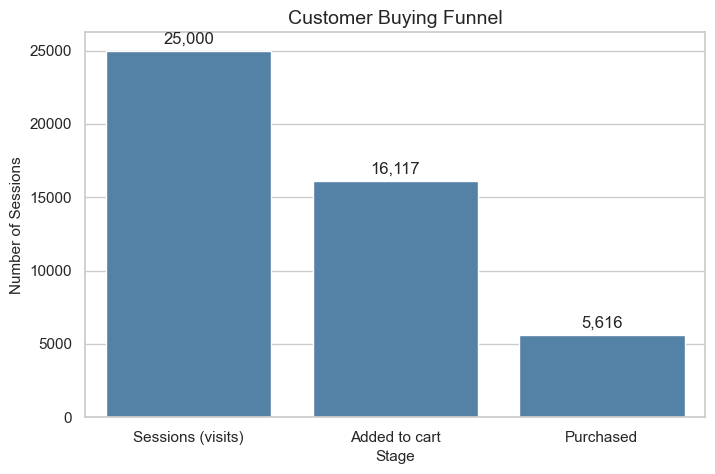

In [116]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(data=funnel, x='Stage', y='Count', color='steelblue')
for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', padding=3)
plt.title('Customer Buying Funnel')
plt.xlabel('Stage')
plt.ylabel('Number of Sessions')
plt.show()

**What this chart shows:** how many sessions reach each stage. Many visitors add products to the cart, but only a smaller group completes the purchase – the gap between the 2nd and 3rd bar is the **lost sales opportunity** (cart abandonment).

# sales analysis

In [117]:
# monthly revenue
monthly_revenue = df.groupby(
    df['visit_date'].dt.to_period('M')
)['revenue'].sum()

monthly_revenue

visit_date
2024-01   904,596.15
2024-02   802,854.34
2024-03   888,857.02
2024-04   820,449.67
2024-05   824,853.58
2024-06   821,460.06
2024-07   797,223.97
2024-08   917,972.70
2024-09   903,900.11
2024-10   802,942.09
2024-11   771,484.47
2024-12   859,574.90
Freq: M, Name: revenue, dtype: float64

In [118]:
# which month generated the highest revenue
monthly_revenue.idxmax(), monthly_revenue.max()

(Period('2024-08', 'M'), np.float64(917972.7))

In [119]:
# which month has the highest purchase
monthly_purchases = df.groupby(
    df['visit_date'].dt.to_period('M')
)['purchased'].sum()

monthly_purchases.idxmax(), monthly_purchases.max()

(Period('2024-08', 'M'), np.int64(502))

In [120]:
# what is the montly conversion rate
monthly_conversion = df.groupby(
    df['visit_date'].dt.to_period('M')
)['purchased'].mean() * 100

monthly_conversion

visit_date
2024-01   23.02
2024-02   22.76
2024-03   22.97
2024-04   22.41
2024-05   21.07
2024-06   23.18
2024-07   21.95
2024-08   23.17
2024-09   23.42
2024-10   21.13
2024-11   21.28
2024-12   23.19
Freq: M, Name: purchased, dtype: float64

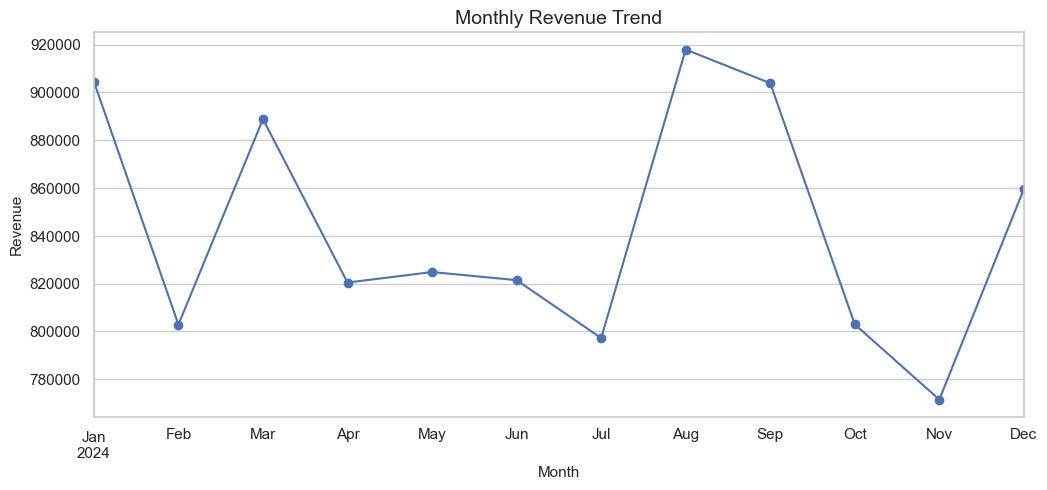

In [121]:
# how revenue changed over time 
monthly_revenue.plot(
    kind='line',
    figsize=(12,5),
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.show()

### Sales trend over time (monthly)

,revenue,orders
year_month,,
2024-01-01,"904,596.15",491
2024-02-01,"802,854.34",458
2024-03-01,"888,857.02",486
2024-04-01,"820,449.67",461
2024-05-01,"824,853.58",437
2024-06-01,"821,460.06",465
2024-07-01,"797,223.97",460
2024-08-01,"917,972.70",502
2024-09-01,"903,900.11",479


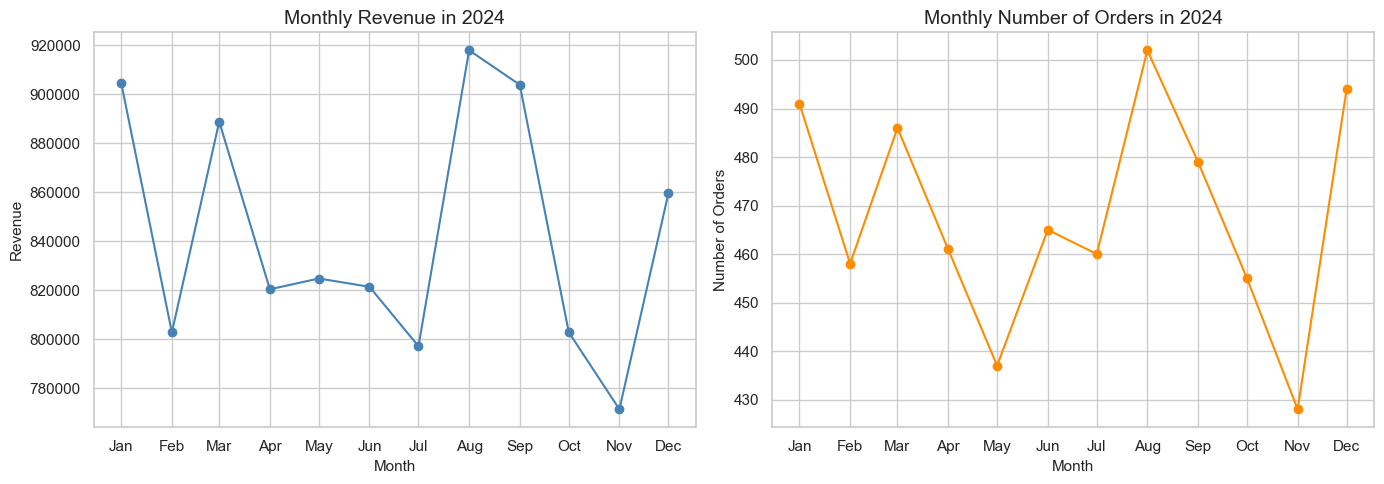

In [122]:
monthly = purchases.groupby('year_month').agg(revenue=('revenue', 'sum'),
                                              orders=('revenue', 'size'))
monthly.index = monthly.index.to_timestamp()
display(monthly)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(monthly.index, monthly['revenue'], marker='o', color='steelblue')
axes[0].set_title('Monthly Revenue in 2024')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Revenue')
axes[0].set_xticks(monthly.index)
axes[0].set_xticklabels(monthly.index.strftime('%b'))

axes[1].plot(monthly.index, monthly['orders'], marker='o', color='darkorange')
axes[1].set_title('Monthly Number of Orders in 2024')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Number of Orders')
axes[1].set_xticks(monthly.index)
axes[1].set_xticklabels(monthly.index.strftime('%b'))

plt.tight_layout()
plt.show()

**What this chart shows:** revenue (left) and number of orders (right) for each month. The two lines move together, which means revenue changes are mainly caused by the **number of orders**. Month-to-month changes are fairly small, so there is no strong seasonal spike in this data.

### Sales by weekday and by season code

,revenue,orders
weekday,,
Monday,"1,446,521.27",823
Tuesday,"1,560,037.48",841
Wednesday,"1,492,304.89",808
Thursday,"1,482,616.09",820
Friday,"1,429,551.70",828
Saturday,"1,383,228.39",756
Sunday,"1,321,909.24",740


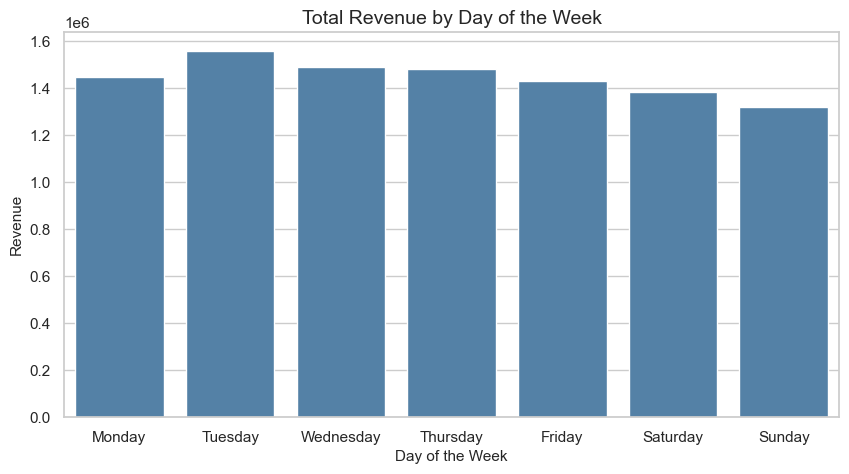

In [123]:
weekday_sales = purchases.groupby('weekday', observed=True).agg(revenue=('revenue', 'sum'),
                                                               orders=('revenue', 'size'))
display(weekday_sales)

plt.figure(figsize=(10, 5))
sns.barplot(x=weekday_sales.index.astype(str), y=weekday_sales['revenue'], color='steelblue')
plt.title('Total Revenue by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Revenue')
plt.show()

**What this chart shows:** total revenue for each weekday. It helps decide on which days to run promotions or add support staff.

In [124]:
# Season is a code in the dataset; the months below are taken from the data itself
season_table = purchases.groupby('visit_season', observed=True).agg(
    months_in_data=('month', lambda s: sorted(s.unique())),
    orders=('revenue', 'size'),
    revenue=('revenue', 'sum'),
    avg_order_value=('revenue', 'mean'))
display(season_table)

,months_in_data,orders,revenue,avg_order_value
visit_season,,,,
0,"[9, 10, 11]",1362,"2,478,326.67","1,819.62"
1,"[3, 4, 5]",1384,"2,534,160.27","1,831.04"
2,"[6, 7, 8]",1427,"2,536,656.73","1,777.62"
3,"[1, 2, 12]",1443,"2,567,025.39","1,778.95"


Each season code covers three months (for example, code 3 covers December, January and February). Revenue is very similar across all four season codes.

### A reusable summary function
Many columns are codes (category, device, channel, ...). To avoid repeating code, we write **one function** that summarises sessions, orders, revenue, conversion rate and average order value for any column.

In [125]:
def segment_summary(column):
    """Summary table for every value of a column (e.g. product_category)."""
    table = df.groupby(column, observed=True).agg(
        sessions=('session_id', 'count'),
        orders=('purchased', 'sum'),
        revenue=('revenue', 'sum'),
        conversion_rate_pct=('purchased', lambda s: s.mean() * 100),
        cart_rate_pct=('added_to_cart', lambda s: s.mean() * 100))
    table['avg_order_value'] = table['revenue'] / table['orders']
    table['revenue_share_pct'] = table['revenue'] / table['revenue'].sum() * 100
    return table

print('Function ready')

Function ready


### Sales by product category

In [126]:
category_summary = segment_summary('product_category')
category_summary['avg_unit_price'] = df.groupby('product_category', observed=True)['unit_price'].mean()
display(category_summary.sort_values('revenue', ascending=False))

,sessions,orders,revenue,conversion_rate_pct,cart_rate_pct,avg_order_value,revenue_share_pct,avg_unit_price
product_category,,,,,,,,
2,3237,721,"2,037,576.79",22.27,63.21,"2,826.04",20.14,"1,238.58"
6,3112,768,"1,930,885.22",24.68,65.10,"2,514.17",19.09,"1,131.58"
5,3149,728,"1,729,167.16",23.12,66.15,"2,375.23",17.09,997.96
3,3040,631,"1,293,649.90",20.76,62.37,"2,050.16",12.79,898.41
7,3073,694,"1,089,617.52",22.58,64.92,"1,570.05",10.77,671.48
0,3142,700,"880,077.03",22.28,65.02,"1,257.25",8.70,579.68
1,3043,647,"702,788.87",21.26,63.49,"1,086.23",6.95,455.72
4,3204,727,"452,406.57",22.69,65.42,622.29,4.47,275.25


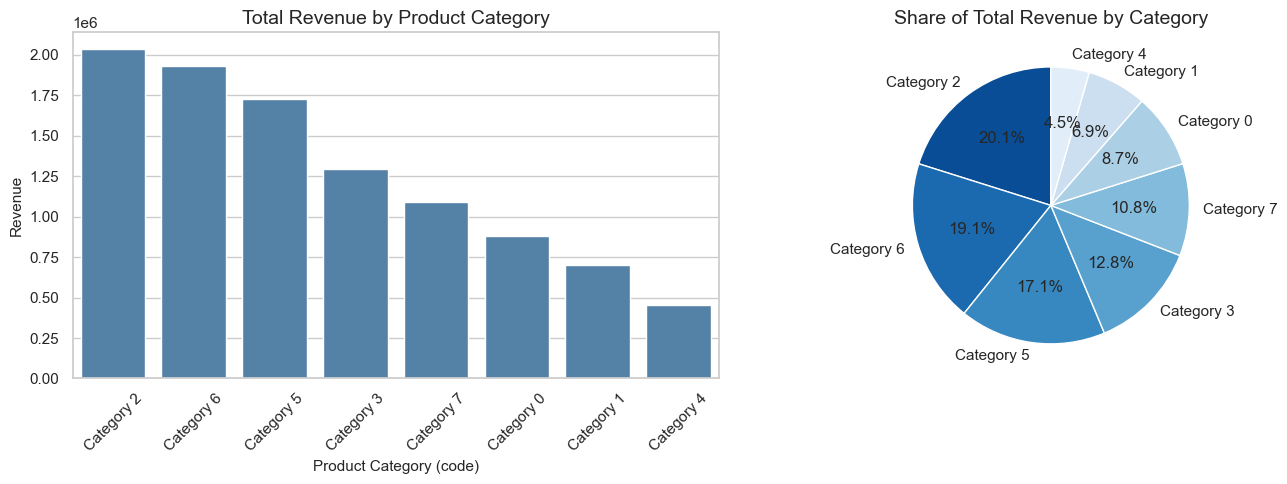

In [127]:
cat_sorted = category_summary.sort_values('revenue', ascending=False)
labels = ['Category ' + str(c) for c in cat_sorted.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart: revenue by category
sns.barplot(x=labels, y=cat_sorted['revenue'], color='steelblue', ax=axes[0])
axes[0].set_title('Total Revenue by Product Category')
axes[0].set_xlabel('Product Category (code)')
axes[0].set_ylabel('Revenue')
axes[0].tick_params(axis='x', rotation=45)

# Pie chart: share of revenue (suitable here because there are only 8 parts of one whole)
axes[1].pie(cat_sorted['revenue'], labels=labels, autopct='%1.1f%%', startangle=90,
            colors=sns.color_palette('Blues_r', len(cat_sorted)))
axes[1].set_title('Share of Total Revenue by Category')

plt.tight_layout()
plt.show()

**What these charts show:** the bar chart ranks categories by revenue and the pie chart shows each category's share of total revenue. A pie chart is suitable here because there are only 8 parts that add up to 100%.

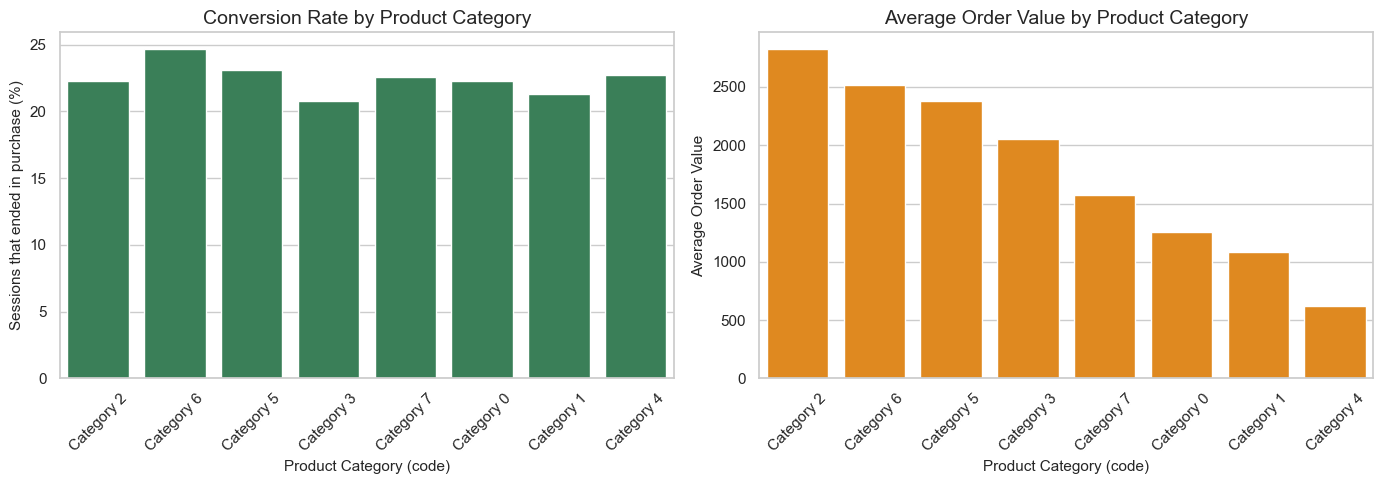

In [128]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=labels, y=cat_sorted['conversion_rate_pct'], color='seagreen', ax=axes[0])
axes[0].set_title('Conversion Rate by Product Category')
axes[0].set_xlabel('Product Category (code)')
axes[0].set_ylabel('Sessions that ended in purchase (%)')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(x=labels, y=cat_sorted['avg_order_value'], color='darkorange', ax=axes[1])
axes[1].set_title('Average Order Value by Product Category')
axes[1].set_xlabel('Product Category (code)')
axes[1].set_ylabel('Average Order Value')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**What these charts show:** *conversion rate* (how often a visit becomes a sale) is similar for all categories, but *average order value* differs a lot. So category revenue differences come mainly from **price level**, not from how often people buy.

### Best-selling products
Products are identified only by `product_id`. We rank them by revenue and by units sold.

In [129]:
product_summary = purchases.groupby('product_id').agg(
    revenue=('revenue', 'sum'),
    units_sold=('quantity', 'sum'),
    orders=('revenue', 'size'))

top_products_revenue = product_summary.sort_values('revenue', ascending=False).head(10)
top_products_units = product_summary.sort_values('units_sold', ascending=False).head(10)

print('Number of different products purchased:', len(product_summary))
print('Share of revenue from the top 10 products: {:.1f}%'.format(
    top_products_revenue['revenue'].sum() / product_summary['revenue'].sum() * 100))

print()
print('Top 10 products by revenue:')
display(top_products_revenue)
print('Top 10 products by units sold:')
display(top_products_units)

Number of different products purchased: 898
Share of revenue from the top 10 products: 3.1%

Top 10 products by revenue:


,revenue,units_sold,orders
product_id,,,
130,"35,975.88",31,12
292,"33,794.75",41,13
806,"32,446.56",35,13
49,"32,122.48",27,9
453,"31,456.73",34,13
696,"30,775.59",32,11
175,"30,099.90",26,10
686,"30,001.75",39,13
634,"29,627.73",27,9


Top 10 products by units sold:


,revenue,units_sold,orders
product_id,,,
292,"33,794.75",41,13
686,"30,001.75",39,13
708,"20,898.35",36,13
324,"20,104.52",36,13
134,"28,171.88",36,12
338,"20,263.76",35,12
18,"20,955.83",35,14
806,"32,446.56",35,13
453,"31,456.73",34,13


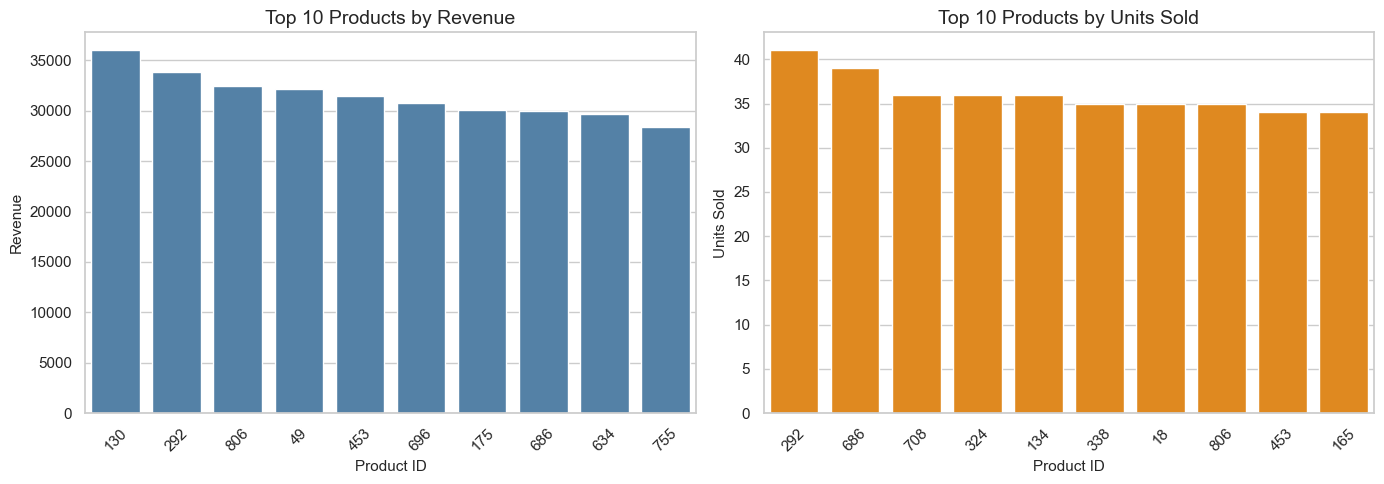

In [130]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=top_products_revenue.index.astype(str), y=top_products_revenue['revenue'],
            color='steelblue', ax=axes[0])
axes[0].set_title('Top 10 Products by Revenue')
axes[0].set_xlabel('Product ID')
axes[0].set_ylabel('Revenue')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(x=top_products_units.index.astype(str), y=top_products_units['units_sold'],
            color='darkorange', ax=axes[1])
axes[1].set_title('Top 10 Products by Units Sold')
axes[1].set_xlabel('Product ID')
axes[1].set_ylabel('Units Sold')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**What these charts show:** the products that earn the most money (left) and the products that sell the most units (right). The two lists are different, because an expensive product can earn a lot with fewer units. The top 10 products together make up only a small share of total revenue, so sales are **spread across many products** and not dependent on a few "hero" products.

# customer analysis

In [131]:
# how many session each customer have
customer_sessions = df.groupby('customer_id')['session_id'].count()

customer_sessions.describe()

count   8,442.00
mean        2.96
std         1.55
min         1.00
25%         2.00
50%         3.00
75%         4.00
max        11.00
Name: session_id, dtype: float64

In [132]:
# which customer generate the highest revenue
customer_revenue = df.groupby('customer_id')['revenue'].sum()

customer_revenue.sort_values(
    ascending=False
).head(10)

customer_id
5176   15,955.15
1738   13,800.96
2994   12,989.28
7574   12,451.97
1334   12,203.21
1506   11,867.10
3645   11,806.82
7744   11,728.23
4004   11,708.76
6256   11,609.37
Name: revenue, dtype: float64

In [133]:
# which customer purchase most frequently
customer_purchases = df.groupby(
    'customer_id'
)['purchased'].sum()

customer_purchases.sort_values(
    ascending=False
).head(10)

customer_id
2939    5
9959    5
4083    5
7015    5
1316    5
9658    5
1334    5
5176    4
7542    4
2688    4
Name: purchased, dtype: int64

In [134]:
# how much custometer are repeat customer
customer_purchases = df.groupby(
    'customer_id'
)['purchased'].sum()

(customer_purchases >= 2).sum()

np.int64(1159)

In [135]:
# how many customer have never purchased
(customer_purchases == 0).sum()

np.int64(4266)

### Top-performing customers and purchase patterns

In [136]:
customer_summary = purchases.groupby('customer_id').agg(
    total_revenue=('revenue', 'sum'),
    orders=('revenue', 'size'),
    units=('quantity', 'sum'))
customer_summary['avg_order_value'] = customer_summary['total_revenue'] / customer_summary['orders']

top_customers = customer_summary.sort_values('total_revenue', ascending=False).head(10)
print('Top 10 customers by revenue:')
display(top_customers)

# Purchase frequency: how many customers bought once, twice, ...
orders_per_customer = customer_summary['orders'].value_counts().sort_index()
repeat_share = (customer_summary['orders'] > 1).mean() * 100
top10pct_n = int(len(customer_summary) * 0.10)
top10pct_share = (customer_summary['total_revenue'].sort_values(ascending=False).head(top10pct_n).sum()
                  / customer_summary['total_revenue'].sum() * 100)

print('Customers who purchased          :', len(customer_summary))
print('Customers with more than 1 order : {:.1f}%'.format(repeat_share))
print('Revenue share of the top 10% of buying customers: {:.1f}%'.format(top10pct_share))

Top 10 customers by revenue:


,total_revenue,orders,units,avg_order_value
customer_id,,,,
5176,"15,955.15",4,10,"3,988.79"
1738,"13,800.96",3,9,"4,600.32"
2994,"12,989.28",3,11,"4,329.76"
7574,"12,451.97",2,8,"6,225.99"
1334,"12,203.21",5,10,"2,440.64"
1506,"11,867.10",4,13,"2,966.78"
3645,"11,806.82",2,8,"5,903.41"
7744,"11,728.23",4,12,"2,932.06"
4004,"11,708.76",3,9,"3,902.92"


Customers who purchased          : 4176
Customers with more than 1 order : 27.8%
Revenue share of the top 10% of buying customers: 28.7%


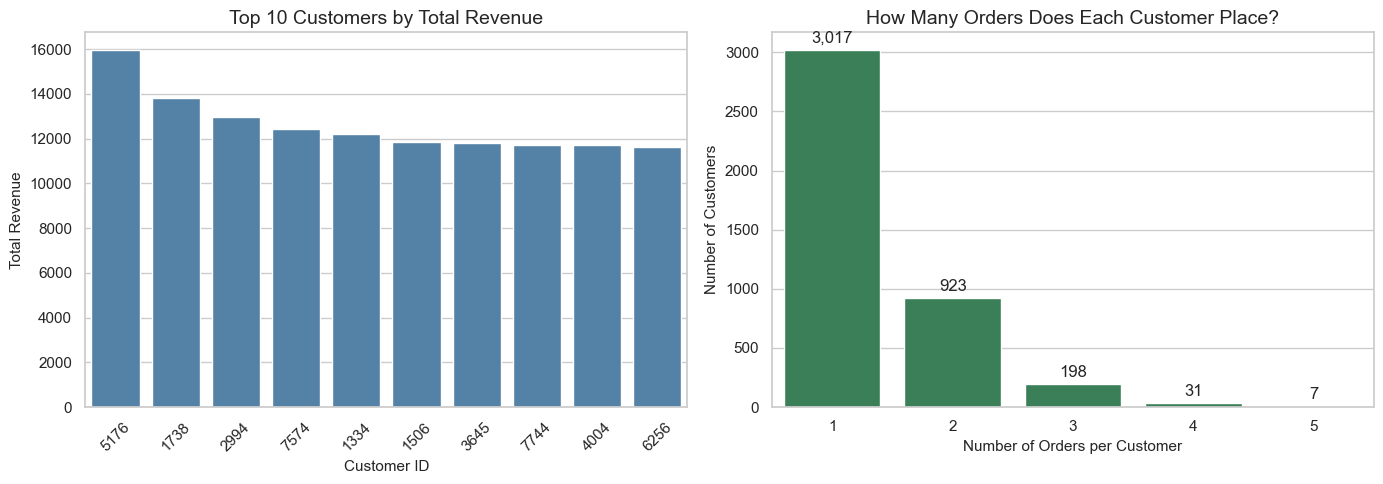

In [137]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=top_customers.index.astype(str), y=top_customers['total_revenue'],
            color='steelblue', ax=axes[0])
axes[0].set_title('Top 10 Customers by Total Revenue')
axes[0].set_xlabel('Customer ID')
axes[0].set_ylabel('Total Revenue')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(x=orders_per_customer.index.astype(str), y=orders_per_customer.values,
            color='seagreen', ax=axes[1])
axes[1].set_title('How Many Orders Does Each Customer Place?')
axes[1].set_xlabel('Number of Orders per Customer')
axes[1].set_ylabel('Number of Customers')
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='{:,.0f}', padding=3)

plt.tight_layout()
plt.show()

**What these charts show:** the customers who spent the most (left) and the number of orders per customer (right). Most customers bought only **once**, so there is a big chance to turn one-time buyers into repeat buyers.

### Regional / location analysis
The dataset has a `location` column, but it is a **numeric code (0–224)**. We cannot name cities or states, so we analyse by location code only.

Number of location codes: 225
Share of revenue from the top 10 locations: 7.0%


,sessions,orders,revenue,conversion_rate_pct,cart_rate_pct,avg_order_value,revenue_share_pct
location,,,,,,,
164,125,35,"76,063.86",28.00,63.20,"2,173.25",0.75
114,134,35,"74,541.67",26.12,62.69,"2,129.76",0.74
63,138,44,"73,156.19",31.88,71.01,"1,662.64",0.72
183,139,34,"72,270.32",24.46,66.19,"2,125.60",0.71
192,123,31,"70,817.44",25.20,69.92,"2,284.43",0.70
222,128,36,"69,534.56",28.12,67.97,"1,931.52",0.69
76,117,29,"69,404.92",24.79,70.09,"2,393.27",0.69
196,109,31,"66,198.85",28.44,66.97,"2,135.45",0.65
31,121,36,"66,180.89",29.75,71.90,"1,838.36",0.65


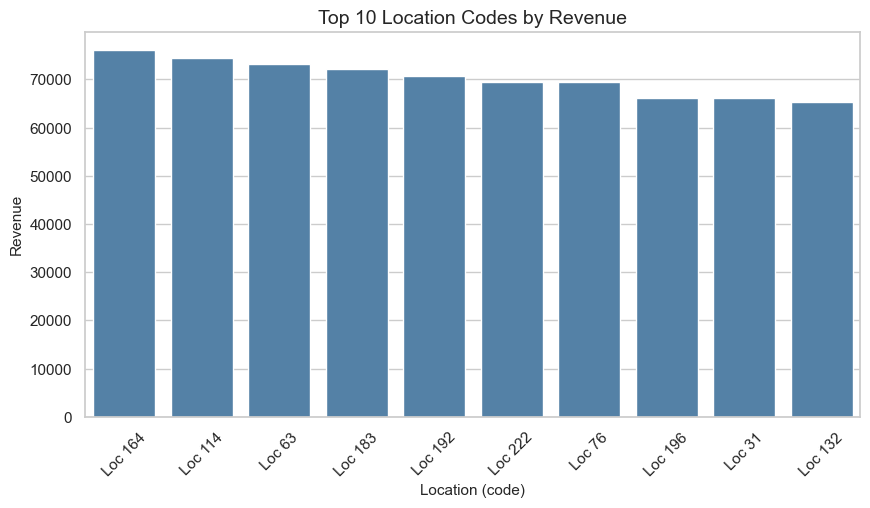

In [138]:
location_summary = segment_summary('location').sort_values('revenue', ascending=False)
print('Number of location codes:', len(location_summary))
print('Share of revenue from the top 10 locations: {:.1f}%'.format(
    location_summary['revenue'].head(10).sum() / location_summary['revenue'].sum() * 100))
display(location_summary.head(10))

top_locations = location_summary.head(10)
plt.figure(figsize=(10, 5))
sns.barplot(x=['Loc ' + str(i) for i in top_locations.index], y=top_locations['revenue'], color='steelblue')
plt.title('Top 10 Location Codes by Revenue')
plt.xlabel('Location (code)')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

**What this chart shows:** the 10 location codes with the highest revenue. Sales are spread over 225 locations, and even the top 10 together only make a small share of total revenue, so no single location dominates.

### Order value and quantity
Histograms show how values are **distributed** (many small values, few large values, and so on).

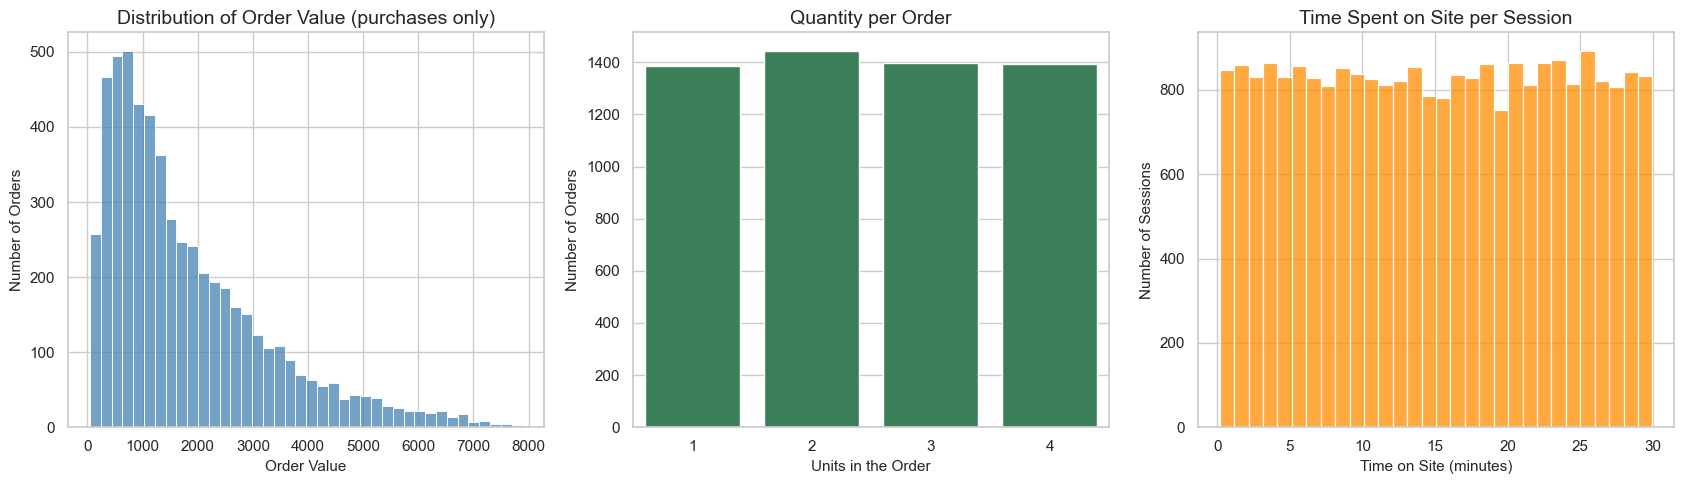

In [139]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.histplot(purchases['revenue'], bins=40, color='steelblue', ax=axes[0])
axes[0].set_title('Distribution of Order Value (purchases only)')
axes[0].set_xlabel('Order Value')
axes[0].set_ylabel('Number of Orders')

sns.countplot(x=purchases['quantity'], color='seagreen', ax=axes[1])
axes[1].set_title('Quantity per Order')
axes[1].set_xlabel('Units in the Order')
axes[1].set_ylabel('Number of Orders')

sns.histplot(df['time_on_site_sec'] / 60, bins=30, color='darkorange', ax=axes[2])
axes[2].set_title('Time Spent on Site per Session')
axes[2].set_xlabel('Time on Site (minutes)')
axes[2].set_ylabel('Number of Sessions')

plt.tight_layout()
plt.show()

**What these charts show:**
- *Order value (left):* most orders are small or medium; a few large orders create a long tail to the right (these are the outliers we kept).
- *Quantity (middle):* how many units customers buy per order (1 to 4).
- *Time on site (right):* time spent per session in minutes, spread fairly evenly from a few seconds to 30 minutes.

# user type analysis

In [140]:
# how does user type affecting purchaseing

df.groupby('user_type')['purchased'].mean() * 100

user_type
0   18.55
1   25.65
Name: purchased, dtype: float64

In [141]:
# how  much revenue each user type genrate
df.groupby('user_type')['revenue'].sum()

user_type
0   3,802,191.52
1   6,313,977.54
Name: revenue, dtype: float64

In [142]:
# how many session come from each user type
user_analysis = df.groupby('user_type').agg(
    sessions=('session_id', 'count'),
    purchases=('purchased', 'sum'),
    revenue=('revenue', 'sum')
)

user_analysis['conversion_rate'] = (
    user_analysis['purchases'] /
    user_analysis['sessions'] * 100
)

user_analysis

,sessions,purchases,revenue,conversion_rate
user_type,,,,
0,11218,2081,"3,802,191.52",18.55
1,13782,3535,"6,313,977.54",25.65


### Customer behaviour by device, user type, marketing channel and payment method
All of these are codes, so we compare codes with each other. The most useful comparison is the **conversion rate** (percentage of sessions that end in a purchase).

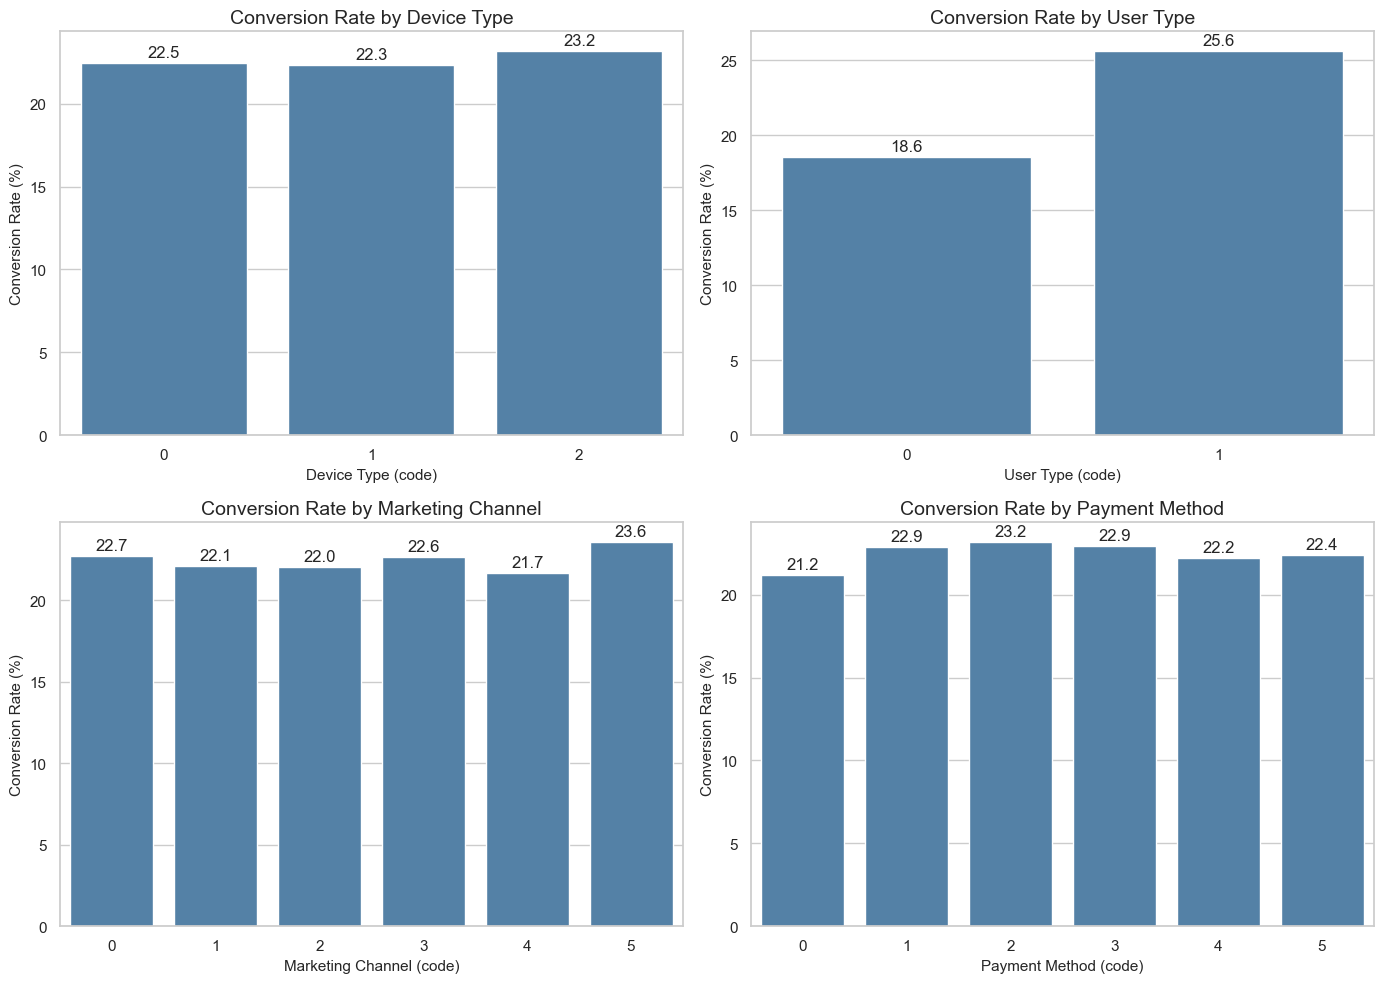

Device Type


,sessions,orders,revenue,conversion_rate_pct,avg_order_value
device_type,,,,,
0,9887,2221,"4,077,146.03",22.46,"1,835.73"
1,12600,2812,"5,006,533.74",22.32,"1,780.42"
2,2513,583,"1,032,489.29",23.20,"1,770.99"


User Type


,sessions,orders,revenue,conversion_rate_pct,avg_order_value
user_type,,,,,
0,11218,2081,"3,802,191.52",18.55,"1,827.10"
1,13782,3535,"6,313,977.54",25.65,"1,786.13"


Marketing Channel


,sessions,orders,revenue,conversion_rate_pct,avg_order_value
marketing_channel,,,,,
0,4041,918,"1,661,328.76",22.72,"1,809.73"
1,4190,927,"1,646,768.68",22.12,"1,776.45"
2,4281,943,"1,711,962.69",22.03,"1,815.44"
3,4116,932,"1,675,463.47",22.64,"1,797.71"
4,4109,890,"1,599,821.67",21.66,"1,797.55"
5,4263,1006,"1,820,823.79",23.60,"1,809.96"


Payment Method


,sessions,orders,revenue,conversion_rate_pct,avg_order_value
payment_method,,,,,
0,4227,895,"1,658,578.47",21.17,"1,853.16"
1,4281,980,"1,704,606.02",22.89,"1,739.39"
2,4051,940,"1,750,767.19",23.20,"1,862.52"
3,4140,949,"1,648,044.55",22.92,"1,736.61"
4,4229,939,"1,691,611.30",22.20,"1,801.50"
5,4072,913,"1,662,561.53",22.42,"1,820.99"


In [143]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
segments = [('device_type', 'Device Type'), ('user_type', 'User Type'),
            ('marketing_channel', 'Marketing Channel'), ('payment_method', 'Payment Method')]

for ax, (col, name) in zip(axes.flatten(), segments):
    summary = segment_summary(col)
    sns.barplot(x=summary.index.astype(str), y=summary['conversion_rate_pct'], color='steelblue', ax=ax)
    ax.set_title('Conversion Rate by ' + name)
    ax.set_xlabel(name + ' (code)')
    ax.set_ylabel('Conversion Rate (%)')
    for container in ax.containers:
        ax.bar_label(container, fmt='%.1f', padding=2)

plt.tight_layout()
plt.show()

for col, name in segments:
    print(name)
    display(segment_summary(col)[['sessions', 'orders', 'revenue', 'conversion_rate_pct', 'avg_order_value']])

**What these charts show:** the percentage of sessions that become purchases for each code. `user_type` code 1 clearly converts better than code 0. The other three columns show only small differences between their codes.

### Effect of discounts

,sessions,orders,revenue,conversion_rate_pct,avg_order_value
discount_percent,,,,,
0,9964,2235,"4,452,869.53",22.43,"1,992.34"
5,2464,550,"1,056,552.22",22.32,"1,921.00"
10,3837,859,"1,534,439.12",22.39,"1,786.31"
15,3748,851,"1,391,492.04",22.71,"1,635.13"
20,2562,584,"938,440.92",22.79,"1,606.92"
25,1186,246,"344,602.91",20.74,"1,400.82"
30,1239,291,"397,772.32",23.49,"1,366.92"


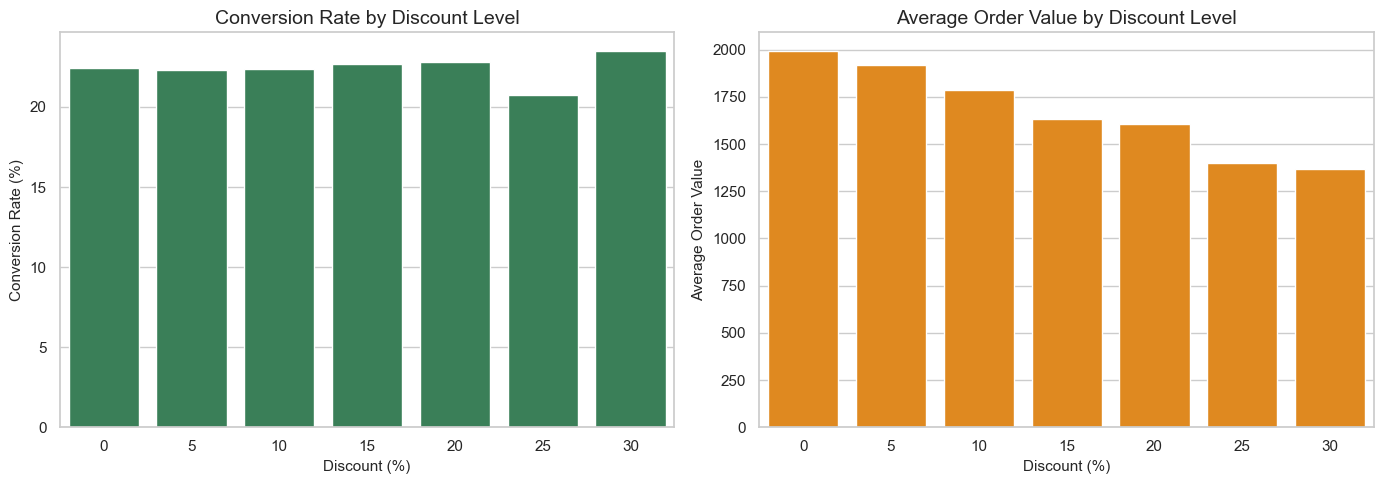

In [144]:
discount_summary = segment_summary('discount_percent')
display(discount_summary[['sessions', 'orders', 'revenue', 'conversion_rate_pct', 'avg_order_value']])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=discount_summary.index.astype(str), y=discount_summary['conversion_rate_pct'],
            color='seagreen', ax=axes[0])
axes[0].set_title('Conversion Rate by Discount Level')
axes[0].set_xlabel('Discount (%)')
axes[0].set_ylabel('Conversion Rate (%)')

sns.barplot(x=discount_summary.index.astype(str), y=discount_summary['avg_order_value'],
            color='darkorange', ax=axes[1])
axes[1].set_title('Average Order Value by Discount Level')
axes[1].set_xlabel('Discount (%)')
axes[1].set_ylabel('Average Order Value')

plt.tight_layout()
plt.show()

**What these charts show:** whether higher discounts lead to more purchases (left) and what they do to the value of each order (right). The conversion rate stays in a narrow band (about 21–24%) with no upward trend as the discount grows, while the average order value falls as the discount grows. In this data, bigger discounts are **not linked with more buying**.

> *Caution:* this is an observation from the data, not proof of cause and effect.

### Quantity and time spent on site

,sessions,orders,revenue,conversion_rate_pct
session_duration_bucket,,,,
Very Short,6270,1269,"2,168,494.60",20.24
Short,6236,1421,"2,609,876.52",22.79
Long,6254,1477,"2,720,865.12",23.62
Very Long,6240,1449,"2,616,932.82",23.22


,orders,revenue
quantity,,
1,1385,"994,539.21"
2,1443,"2,061,672.16"
3,1396,"2,992,531.21"
4,1392,"4,067,426.48"


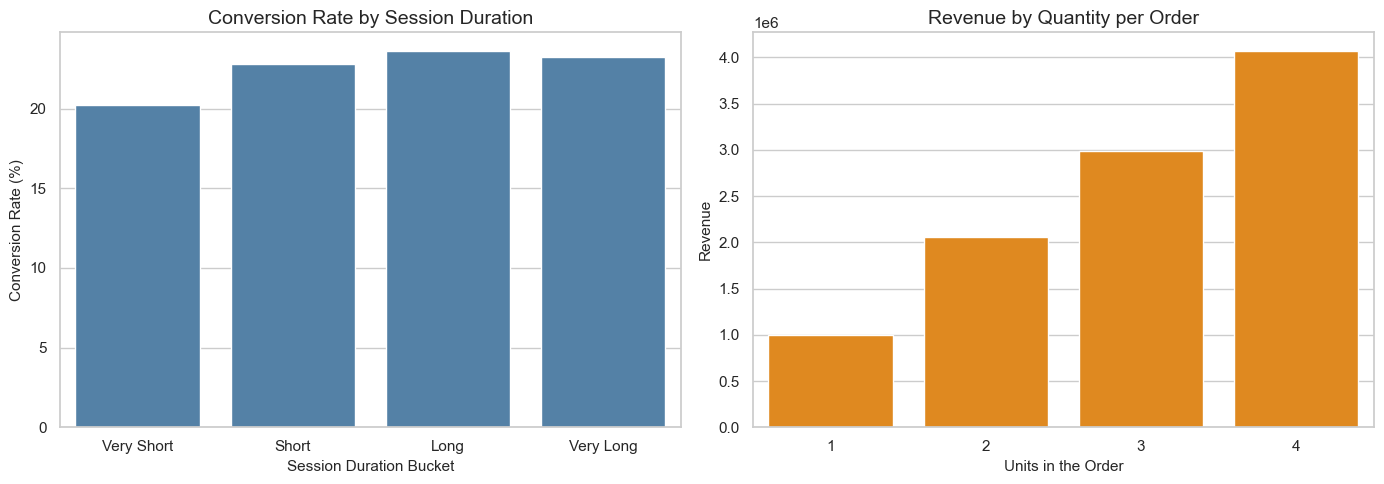

In [145]:
duration_order = ['Very Short', 'Short', 'Long', 'Very Long']
duration_summary = (df.groupby('session_duration_bucket')
                      .agg(sessions=('session_id', 'count'),
                           orders=('purchased', 'sum'),
                           revenue=('revenue', 'sum'),
                           conversion_rate_pct=('purchased', lambda s: s.mean() * 100))
                      .reindex(duration_order))
display(duration_summary)

quantity_summary = purchases.groupby('quantity').agg(orders=('revenue', 'size'), revenue=('revenue', 'sum'))
display(quantity_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=duration_summary.index, y=duration_summary['conversion_rate_pct'], color='steelblue', ax=axes[0])
axes[0].set_title('Conversion Rate by Session Duration')
axes[0].set_xlabel('Session Duration Bucket')
axes[0].set_ylabel('Conversion Rate (%)')

sns.barplot(x=quantity_summary.index.astype(str), y=quantity_summary['revenue'], color='darkorange', ax=axes[1])
axes[1].set_title('Revenue by Quantity per Order')
axes[1].set_xlabel('Units in the Order')
axes[1].set_ylabel('Revenue')

plt.tight_layout()
plt.show()

**What these charts show:** very short sessions convert less often than longer ones (left), and orders with more units bring much more revenue (right).

### Ratings and reviews (purchasing sessions only)
As found in the cleaning stage, non-purchasing sessions all carry the same rating of 4, so only purchase rows are used here. `review_text` is only a number, so no text analysis is possible and this column is **skipped**.

Average rating of purchases: 3.77
Share of purchases rated 1 or 2: 14.5%


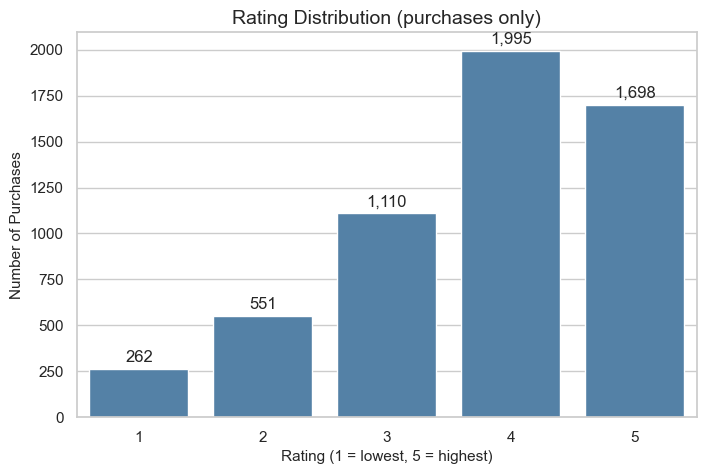

In [146]:
rating_counts = purchases['rating'].value_counts().sort_index()
print('Average rating of purchases: {:.2f}'.format(purchases['rating'].mean()))
print('Share of purchases rated 1 or 2: {:.1f}%'.format((purchases['rating'] <= 2).mean() * 100))

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=rating_counts.index.astype(str), y=rating_counts.values, color='steelblue')
ax.bar_label(ax.containers[0], fmt='{:,.0f}', padding=3)
plt.title('Rating Distribution (purchases only)')
plt.xlabel('Rating (1 = lowest, 5 = highest)')
plt.ylabel('Number of Purchases')
plt.show()

**What this chart shows:** how customers who purchased rated their experience. About two-thirds of ratings are 4 or 5, but a visible group gave low ratings (1 or 2) – a group worth investigating.

### Correlation heatmap
Correlation measures how strongly two **numeric** columns move together (from −1 to +1). We only include meaningful numeric columns. Identifiers, codes, date parts, `revenue_normalized` (a copy of revenue) and `rating` (not real for non-buyers) are left out.

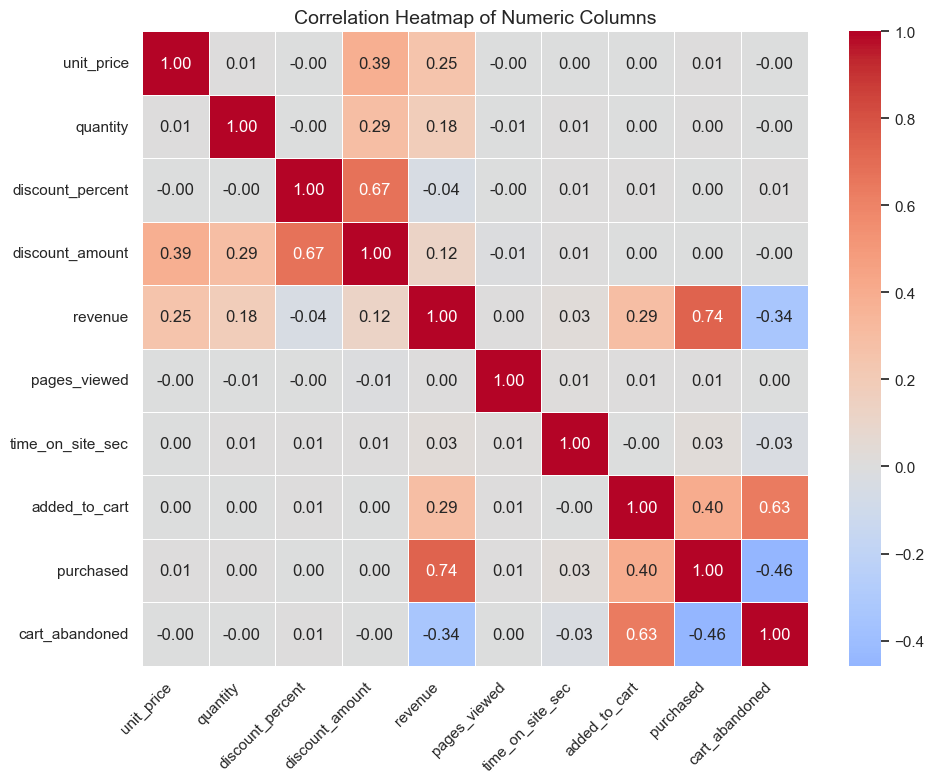

,correlation_with_revenue
purchased,0.74
added_to_cart,0.29
unit_price,0.25
quantity,0.18
discount_amount,0.12
time_on_site_sec,0.03
pages_viewed,0.00
discount_percent,-0.04
cart_abandoned,-0.34


In [147]:
numeric_columns = ['unit_price', 'quantity', 'discount_percent', 'discount_amount', 'revenue',
                   'pages_viewed', 'time_on_site_sec', 'added_to_cart', 'purchased', 'cart_abandoned']
correlation = df[numeric_columns].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation Heatmap of Numeric Columns')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# The strongest relationships with revenue
display(correlation['revenue'].drop('revenue').sort_values(ascending=False).to_frame('correlation_with_revenue'))

**What this chart shows:** red = move together, blue = move in opposite directions, white = no relationship.
- `revenue` has a strong positive link with `purchased` (about 0.74), which is expected because revenue is zero when nothing is bought. Its links with `unit_price` (about 0.25) and `quantity` (about 0.18) are weaker, because most sessions have zero revenue.
- `discount_amount` is linked with `discount_percent` (about 0.67), `unit_price` (about 0.39) and `quantity` (about 0.29), because it is calculated from them.
- `unit_price`, `quantity`, `discount_percent`, `pages_viewed` and `time_on_site_sec` all have **almost no correlation (close to 0) with `purchased`**, so price, discount and browsing activity alone do not explain who buys in this data.
- `purchased` and `cart_abandoned` are negatively related (about -0.46) because a cart is only counted as abandoned when it was not purchased.

## Business Insights

All findings below come from the numbers calculated in this notebook for the 2024 data (25,000 sessions).

| # | Finding | Evidence from the data |
|---|---|---|
| 1 | **Overall performance** | 5,616 of 25,000 sessions ended in a purchase (**22.5% conversion**). Total revenue was about **10.12 million** with an average order value of about **1,801** (median about 1,352). |
| 2 | **Cart abandonment is the biggest leak** | 64.5% of sessions added a product to the cart, but only **34.8% of those carts were bought**. About **65% of carts were abandoned**. |
| 3 | **A few categories drive most revenue** | Categories **2, 6 and 5** give about **56%** of revenue. Category **4** is the lowest (about 0.45 million) because its products are cheap (average order value about 622). |
| 4 | **Revenue differences between categories come from price, not demand** | Conversion rates are all between about 20.8% and 24.7%, but average order value ranges from about 622 to about 2,826. Category 6 has the best conversion rate (24.7%). |
| 5 | **Sales are spread widely – no hero product** | 898 different products were bought and the top 10 products make only about **3.1%** of revenue. The top 10 locations (out of 225) make only about **7%**. |
| 6 | **Most customers buy only once** | Of 4,176 customers who purchased, **72%** bought once and **28%** bought again. The top 10% of buyers give about **29%** of revenue. |
| 7 | **Revenue is stable through the year** | Monthly revenue stayed between about 771 thousand (November, the lowest) and 918 thousand (August, the highest), with no strong seasonal peak. |
| 8 | **Weekends are slightly weaker** | Tuesday has the highest revenue (about 1.56 million) and Sunday the lowest (about 1.32 million). Saturday and Sunday also have fewer orders (756 and 740) than weekdays (about 810–840). |
| 9 | **Discounts do not seem to increase purchases** | The conversion rate stays in a narrow band (about 20.7% to 23.5%) with no upward trend from 0% to 30% discount, but the average order value falls from about **1,992 (no discount)** to about **1,367 (30% discount)**. About 0.99 million (8.9% of gross sales) was given away in discounts. |
| 10 | **Buying more units drives revenue** | Orders with 4 units give about 4.07 million revenue (about 40% of the total) against about 0.99 million for single-unit orders, although the conversion rate is the same for all quantities. |
| 11 | **User type 1 converts better** | User type code 1 converts at **25.6%** against **18.6%** for code 0, and brings about 62% of revenue. Device, marketing channel and payment method differ only slightly (about 21–24%). |
| 12 | **Very short visits rarely buy** | Sessions in the "Very Short" bucket convert at about 20.2%, compared with 22.8–23.6% for the other buckets. Pages viewed is almost the same for buyers and non-buyers (about 12.6 vs 12.5). |
| 13 | **Customer satisfaction needs attention** | The average rating of purchases is 3.77 and about 14.5% of purchases were rated 1 or 2. |

### Recommendations
**To improve sales**
1. **Reduce cart abandonment** – send reminders to people who leave items in the cart, simplify checkout and show delivery cost early. A small improvement in the 34.8% cart-to-purchase rate has a large effect on revenue.
2. **Review the discount policy** – discounts above 0% did not raise the conversion rate but lowered the order value. Use targeted discounts (for example, for abandoned carts) instead of broad discounts.
3. **Encourage bigger baskets** – offer bundles or "buy more, save more" offers, because orders with more units bring much more revenue.
4. **Grow the high-value categories** – promote categories 2, 6 and 5; look for ways to increase the basket size in low-price Category 4.

**To understand and keep customers**
5. **Create a loyalty or repeat-purchase programme** – 72% of buyers purchased only once. Follow-up emails and reward points can turn them into repeat buyers.
6. **Study the best customers** – the top 10% of buyers give about 29% of revenue, so offer them special services.
7. **Investigate low ratings** – find the reasons behind the ratings of 1 and 2 (delivery, quality, price) and fix them.

**To support business decisions**
8. **Plan promotions** – weekdays (especially Tuesday) perform best; weekend campaigns could be tested to lift Saturday and Sunday.
9. **Learn from user type 1** – find out what makes this group convert better and apply it to type 0.
10. **Improve data quality** – record the meaning of the codes (device, channel, category, location) and use real review text, so deeper analysis becomes possible.

## Conclusion

**Summary of the work:** We loaded 25,000 e-commerce sessions, explored and checked them, confirmed that there were no missing or duplicate values, fixed the date and category data types, verified the data with eight logic checks, and then analysed sales, products, categories, customers, locations, discounts and customer behaviour with tables and charts.

**Important findings:**
- The store earned about 10.1 million from 5,616 orders (22.5% conversion rate, average order value about 1,801).
- The biggest weakness is **cart abandonment** – about 65% of carts are not completed.
- Revenue depends on **price level and basket size** much more than on how often people buy.
- Sales are spread across many products and locations; most customers buy only once.
- Larger discounts did not lead to more purchases in this data.

**Limitations:**
- Many columns (device, user type, channel, category, payment method, location) are **codes without a dictionary**, so we cannot say what they represent in real life.
- The data covers **only one year (2024)**, so yearly patterns and growth cannot be studied.
- The data is **session-level**; revenue is zero for sessions without a purchase. There is no cost or profit information, so profit cannot be calculated.
- `review_text` is only a number, and ratings of non-buyers look like a default value.
- The findings show **relationships, not proof of cause and effect**.
- Currency is not stated.

**Possible future improvements:**
- Add a data dictionary and decode the code columns (real category, city and device names).
- Add cost and profit data to measure profitability.
- Add data from more years for trend and seasonality analysis.
- Build customer segments (for example, using RFM – recency, frequency, monetary value).
- Use simple predictive models (for example, to predict cart abandonment) once the basics are mastered.
- Build an interactive dashboard in Power BI or Tableau.